Importamos librerias para conectar y manejar los datos

In [23]:
import sqlite3 as scl
import pandas as pd
import matplotlib.pyplot as pl

Creamos la conexion a nuestra base de datos

In [24]:
conexion = scl.connect("../bases_datos/ventas.db")

Vamos a escribir de las consultas SQL, asignarlos a variables, para obtener los indicadores Primero con el margen medio de categoría.

In [25]:
conMargenCategoria = """
SELECT IdCategoria,
AVG(PrecioVenta) AS MargenMedio
FROM Productos
GROUP BY IdCategoria ORDER BY MargenMedio DESC;
"""
conClientesProvincia = """
SELECT Provincia, COUNT(*) AS TotalClientes
FROM Clientes
GROUP BY Provincia ORDER BY TotalClientes DESC;
"""
conTop3Productos = """
SELECT IdProducto, SUM(Cantidad) AS Unidades
FROM LineasVenta
GROUP BY IdProducto
ORDER BY Unidades DESC LIMIT 3;
"""
conTop5EurosProductos = """
SELECT IdProducto, SUM((PrecioUnitario*Cantidad)-(PrecioUnitario*Cantidad*(Descuento/100))) AS ImporteTotal
FROM LineasVenta
GROUP BY IdProducto
ORDER BY ImporteTotal DESC LIMIT 5;
"""
conTop3StockCategoria = """
SELECT IdCategoria, SUM(Stock) AS StockTotal
FROM Productos
GROUP BY IdCategoria ORDER BY StockTotal DESC LIMIT 3;
"""


Pasamos las consultas a la base de datos con pandas y guardamos los resultados en objetos dataframe de pyrhon.

In [26]:
dfMargenCategoria = pd.read_sql_query(conMargenCategoria, conexion)
dfClientesProvincia = pd.read_sql_query(conClientesProvincia, conexion)
dfTop3Productos = pd.read_sql_query(conTop3Productos, conexion)
dfTop5EurosProductos = pd.read_sql_query(conTop5EurosProductos, conexion)
dfTop3Stock = pd.read_sql_query(conTop3StockCategoria, conexion)


Margen medio por categoria
   IdCategoria  MargenMedio
0            1   250.700000
1            3   172.333333
2            5   163.333333
3            4    54.000000
4            2     7.133333

Ranking de clientes por provincia
  Provincia  TotalClientes
0  Alicante              7
1  Valencia              2
2    Murcia              2
3    Madrid              1



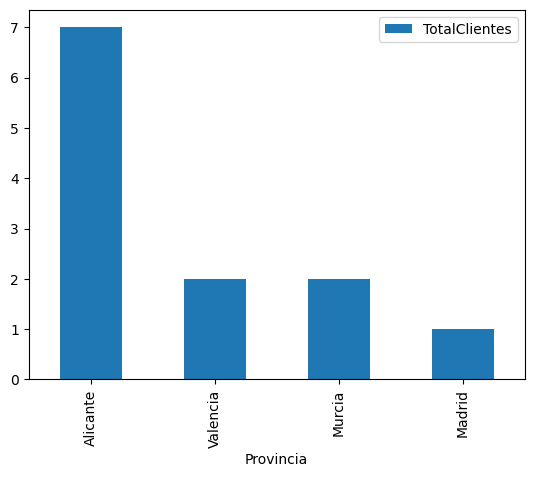

Los 3 productos mas vendidos
   IdProducto  Unidades
0           5       140
1           6        55
2          11        37

Los 5 prodcutos que mas euros nos generan
   IdProducto  ImporteTotal
0           1       4602.24
1           2       2226.00
2          14       1975.00
3           8       1864.05
4          11       1073.00

Top 3 productos con mas stock
   IdCategoria  StockTotal
0            5        2997
1            2         440
2            1         193

Fin del informe


In [28]:
print("Margen medio por categoria")
print(dfMargenCategoria)
print()
print("Ranking de clientes por provincia")
print(dfClientesProvincia)
print()
dfClientesProvincia.plot(kind='bar',x='Provincia',y='TotalClientes')
pl.show()
print("Los 3 productos mas vendidos")
print(dfTop3Productos)
print()
print("Los 5 prodcutos que mas euros nos generan")
print(dfTop5EurosProductos)
print()
print("Top 3 productos con mas stock")
print(dfTop3Stock)
print()
print("Fin del informe")
